Implementation and setup:-

In [4]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

def build_U(n):
    """Binary-fraction phase oracle: U|x> = exp(2*pi*i*x/2^n)|x>."""
    qc = QuantumCircuit(n, name=f"U{n}")
    for j in range(n):  # j = 0 is the least-significant bit
        qc.p(2 * np.pi * 2**j / 2**n, j)
    return qc


def prepare_basis_state(qc, target, x):
    for j, q in enumerate(target):
        if (x >> j) & 1:
            qc.x(q)


def inverse_qft(qc, qubits):
    m = len(qubits)

    for i in range(m // 2):
        qc.swap(qubits[i], qubits[m - 1 - i])

    for j in range(m):
        for k in range(j):
            qc.cp(-np.pi / 2**(j - k), qubits[k], qubits[j])
        qc.h(qubits[j])


def qpe_circuit(U, n, m, prepare):
    qc = QuantumCircuit(m + n, m)

    count = list(range(m))       # Counting qubits 0 ... m-1
    target = list(range(m, m+n)) # Target qubits m ... m+n-1

    prepare(qc, target)

    # TODO 1: Apply H to every counting qubit
    for k in range(m):
        qc.h(count[k])

    # TODO 2: Counting qubit k controls U^(2^k)
    for k in range(m):
        controlled_U = U.to_gate().control(1)
        for _ in range(2**k):
            qc.append(controlled_U, [count[k]] + target)

    # TODO 3: Apply inverse QFT
    inverse_qft(qc, count)

    # TODO 4: Measure counting qubit k into classical bit k
    for k in range(m):
        qc.measure(count[k], k)

    return qc


def run(qc, shots=2048):
    sim = AerSimulator()
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()


def decode(bitstring):
    return int(bitstring, 2) / 2**len(bitstring)


# Example: n = 3, |v> = |101>, m = 3
qc = qpe_circuit(
    build_U(3),
    3,
    3,
    lambda qc, t: prepare_basis_state(qc, t, 5)
)

qc = qpe_circuit(build_U(3), 3, 3, lambda qc, t: prepare_basis_state(qc, t, 5))

Sanity check:-

In [5]:
#Target state |000>
qc_zero = qpe_circuit(
    build_U(3),
    3,
    3,
    lambda qc, t: prepare_basis_state(qc, t, 0)
)

# Run the circuit
counts_zero = run(qc_zero)

print("Measurement results:", counts_zero)


Measurement results: {'000': 2048}


-------------------------------------------------------------------------------------------------------------------------------

Part A:-

Initial Predictions Before Running.:-

In [6]:
import pandas as pd
predictions = [
    ["A1", 1, "|1>", "0.1", 1, "Yes", "1"],
    ["A2", 1, "|1>", "0.1", 2, "Yes", "10"],
    ["A3", 1, "|1>", "0.1", 3, "Yes", "100"],
    ["A4", 2, "|11>", "0.11", 1, "No", "0 and 1 (tie)"],
    ["A5", 2, "|11>", "0.11", 2, "Yes", "11"],
    ["A6", 2, "|11>", "0.11", 3, "Yes", "110"],
    ["A7", 3, "|101>", "0.101", 1, "No", "1"],
    ["A8", 3, "|101>", "0.101", 2, "No", "10 and 11 (tie)"],
    ["A9", 3, "|101>", "0.101", 3, "Yes", "101"],
    ["A10", 4, "|1011>", "0.1011", 1, "No", "1"],
    ["A11", 4, "|1011>", "0.1011", 2, "No", "11"],
    ["A12", 4, "|1011>", "0.1011", 3, "No", "101 and 110 (tie)"],
    ["A13", 4, "|1000>", "0.1000", 1, "Yes", "1"],
    ["A14", 4, "|1000>", "0.1000", 2, "Yes", "10"],
    ["A15", 4, "|1000>", "0.1000", 3, "Yes", "100"]
]

df_predictions = pd.DataFrame(
    predictions,
    columns=[
        "Run", "n", "Target state", "True phase",
        "m", "Prediction: exact?", "Predicted most likely outcome"
    ]
)

display(df_predictions)


,Run,n,Target state,True phase,m,Prediction: exact?,Predicted most likely outcome
0,A1,1,|1>,0.1,1,Yes,1
1,A2,1,|1>,0.1,2,Yes,10
2,A3,1,|1>,0.1,3,Yes,100
3,A4,2,|11>,0.11,1,No,0 and 1 (tie)
4,A5,2,|11>,0.11,2,Yes,11
5,A6,2,|11>,0.11,3,Yes,110
6,A7,3,|101>,0.101,1,No,1
7,A8,3,|101>,0.101,2,No,10 and 11 (tie)
8,A9,3,|101>,0.101,3,Yes,101
9,A10,4,|1011>,0.1011,1,No,1


After Running and Recording all Results:-

In [7]:

import numpy as np
import matplotlib.pyplot as plt

# Target states for Part A
experiments = [
    (1, 1),    # n=1, x=1
    (2, 3),    # n=2, x=3
    (3, 5),    # n=3, x=5
    (4, 11),   # n=4, x=11
    (4, 8)     # n=4, x=8
]

shots = 2048
results_A = {}

# Run all 15 experiments
for n, x in experiments:

    for m in range(1, 4):

        run_id = f"A{len(results_A) + 1}"

        # Construct QPE circuit
        qc = qpe_circuit(
            build_U(n),
            n,
            m,
            lambda qc, t, x=x: prepare_basis_state(qc, t, x)
        )

        # Run simulation
        counts = run(qc, shots=shots)

        # True phase
        phi = x / (2**n)

        # Most likely outcome
        most_likely = max(counts, key=counts.get)
        y = int(most_likely, 2)

        # Estimated phase
        phi_est = y / (2**m)

        # Measured probability
        measured_prob = counts[most_likely] / shots

        # Theoretical exactness
        exact = np.isclose(phi * (2**m), round(phi * (2**m)))

        # Store results
        results_A[run_id] = {
            "n": n,
            "x": x,
            "m": m,
            "phi": phi,
            "counts": counts,
            "y": y,
            "most_likely": most_likely,
            "phi_est": phi_est,
            "measured_prob": measured_prob,
            "exact": exact
        }

        print(f"\n{run_id}: n={n}, m={m}")
        print("Measurement results:", counts)
        print("Most likely outcome:", most_likely)
        print("Estimated phase:", phi_est)
        print("Probability:", measured_prob)
        print("Exact:", exact)



A1: n=1, m=1
Measurement results: {'1': 2048}
Most likely outcome: 1
Estimated phase: 0.5
Probability: 1.0
Exact: True

A2: n=1, m=2
Measurement results: {'10': 2048}
Most likely outcome: 10
Estimated phase: 0.5
Probability: 1.0
Exact: True

A3: n=1, m=3
Measurement results: {'100': 2048}
Most likely outcome: 100
Estimated phase: 0.5
Probability: 1.0
Exact: True

A4: n=2, m=1
Measurement results: {'0': 1013, '1': 1035}
Most likely outcome: 1
Estimated phase: 0.5
Probability: 0.50537109375
Exact: False

A5: n=2, m=2
Measurement results: {'11': 2048}
Most likely outcome: 11
Estimated phase: 0.75
Probability: 1.0
Exact: True

A6: n=2, m=3
Measurement results: {'110': 2048}
Most likely outcome: 110
Estimated phase: 0.75
Probability: 1.0
Exact: True

A7: n=3, m=1
Measurement results: {'0': 292, '1': 1756}
Most likely outcome: 1
Estimated phase: 0.5
Probability: 0.857421875
Exact: False

A8: n=3, m=2
Measurement results: {'01': 162, '00': 135, '11': 914, '10': 837}
Most likely outcome: 11
E

Generating One Histogram per n:-

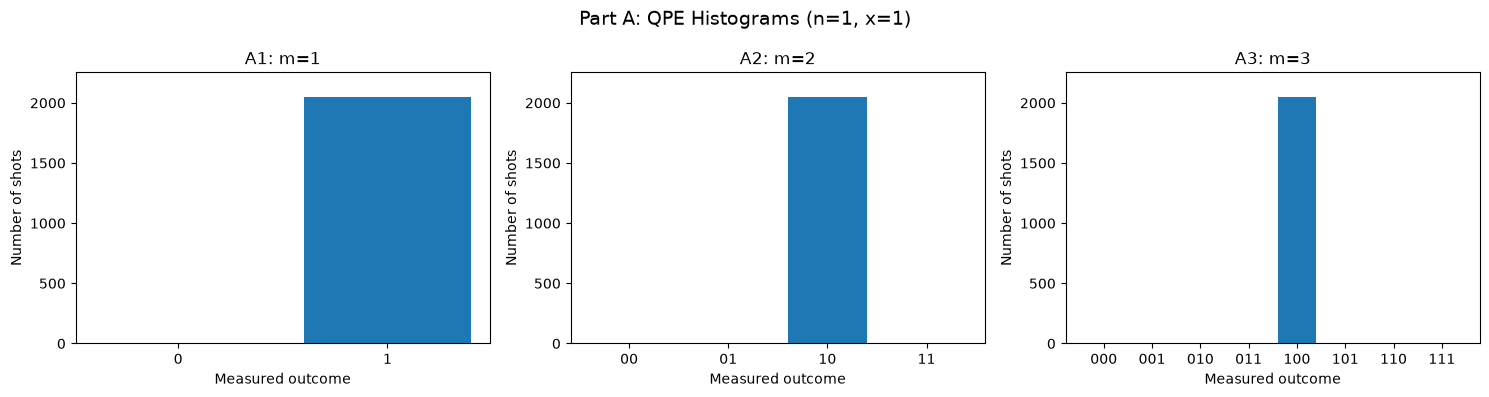

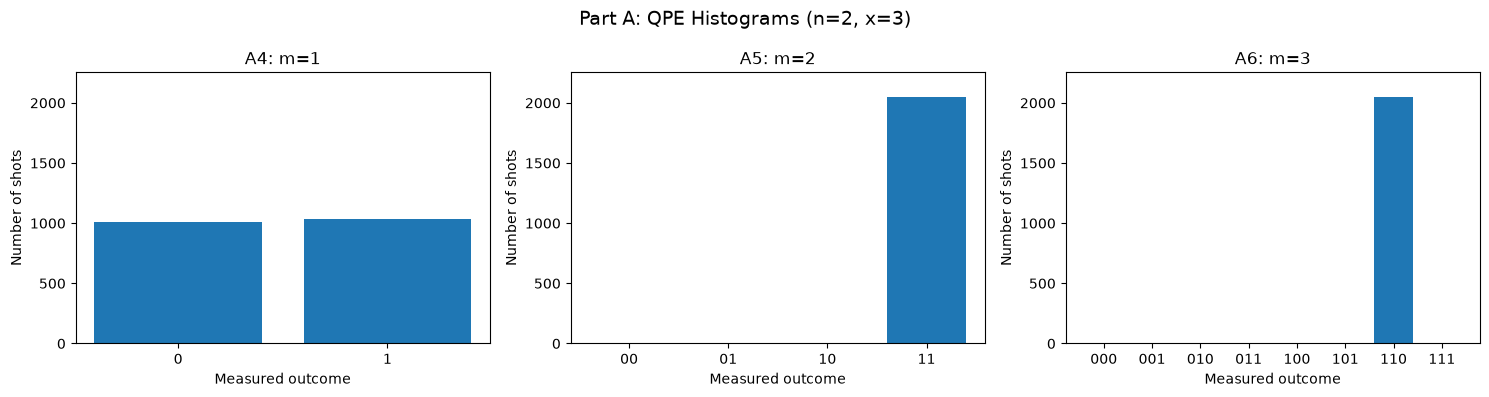

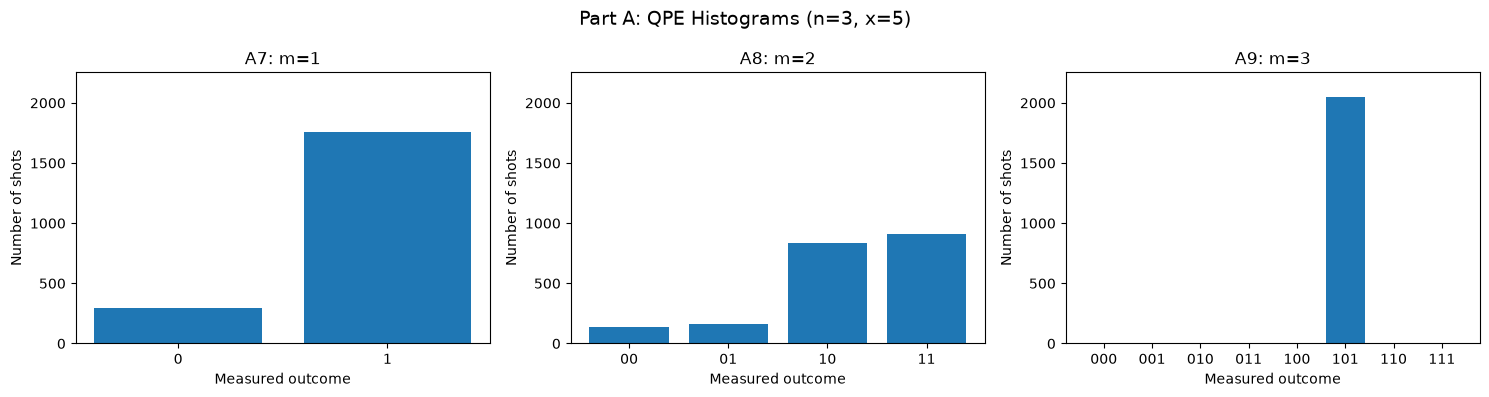

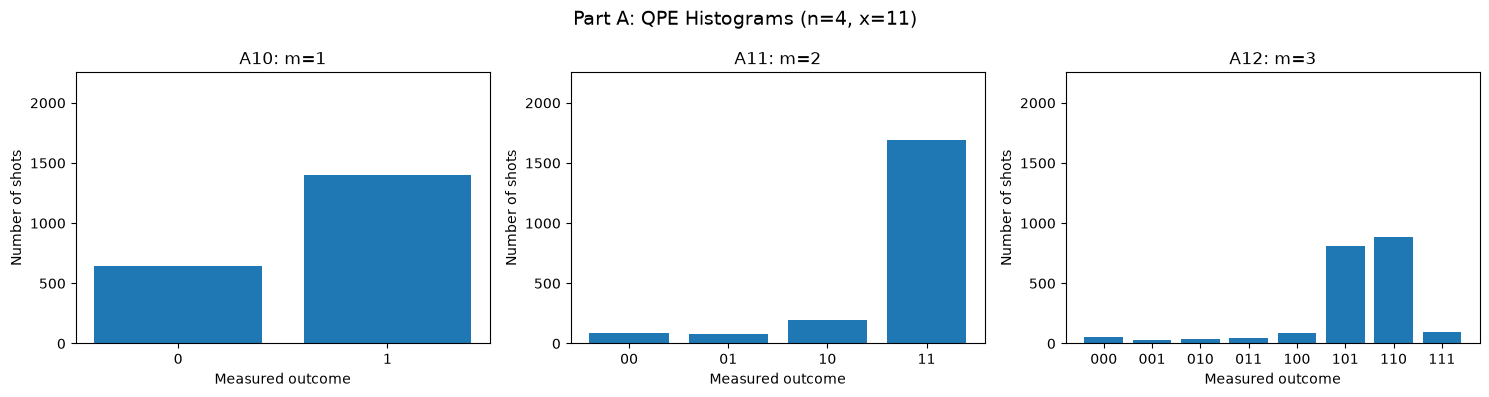

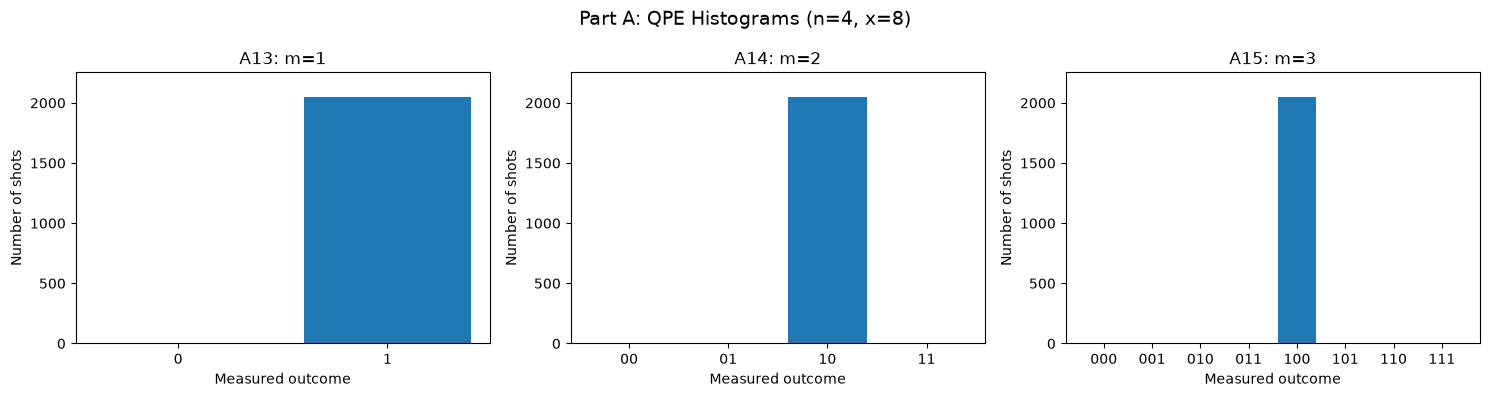

In [8]:

# Generate one figure per target state,
# with m = 1, 2, 3 displayed side by side.

for n, x in experiments:

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for m, ax in zip(range(1, 4), axes):

        run_id = next(
            key for key, value in results_A.items()
            if value["n"] == n
            and value["x"] == x
            and value["m"] == m
        )

        result = results_A[run_id]
        counts = result["counts"]

        # Include all possible outcomes, even if count is zero
        outcomes = [
            format(y, f"0{m}b") for y in range(2**m)
        ]

        frequencies = [
            counts.get(outcome, 0) for outcome in outcomes
        ]

        ax.bar(outcomes, frequencies)
        ax.set_title(f"{run_id}: m={m}")
        ax.set_xlabel("Measured outcome")
        ax.set_ylabel("Number of shots")
        ax.set_ylim(0, shots * 1.1)

    fig.suptitle(
        f"Part A: QPE Histograms (n={n}, x={x})",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


Completed Results Table After Running:-

In [9]:
#Completed table
print(
    f"{'Run':<6} {'n':<3} {'m':<3} "
    f"{'True phase':<12} {'Prediction':<12} "
    f"{'Most likely y':<15} {'Estimated phase':<17} "
    f"{'Measured P':<12} {'Exact?'}"
)

for run_id, r in results_A.items():

    prediction = "Yes" if r["exact"] else "No"

    print(
        f"{run_id:<6} "
        f"{r['n']:<3} "
        f"{r['m']:<3} "
        f"{r['phi']:<12.4f} "
        f"{prediction:<12} "
        f"{r['most_likely']:<15} "
        f"{r['phi_est']:<17.4f} "
        f"{r['measured_prob']:<12.4f} "
        f"{'Yes' if np.isclose(r['phi'], r['phi_est']) else 'No'}"
    )


Run    n   m   True phase   Prediction   Most likely y   Estimated phase   Measured P   Exact?
A1     1   1   0.5000       Yes          1               0.5000            1.0000       Yes
A2     1   2   0.5000       Yes          10              0.5000            1.0000       Yes
A3     1   3   0.5000       Yes          100             0.5000            1.0000       Yes
A4     2   1   0.7500       No           1               0.5000            0.5054       No
A5     2   2   0.7500       Yes          11              0.7500            1.0000       Yes
A6     2   3   0.7500       Yes          110             0.7500            1.0000       Yes
A7     3   1   0.6250       No           1               0.5000            0.8574       No
A8     3   2   0.6250       No           11              0.7500            0.4463       No
A9     3   3   0.6250       Yes          101             0.6250            1.0000       Yes
A10    4   1   0.6875       No           1               0.5000            0.684

Theoretical Probability Comparison:-

In [10]:

def theoretical_probability(phi, m, y):

    N = 2**m

    total = sum(
        np.exp(2j * np.pi * j * (phi - y/N))
        for j in range(N)
    )

    return abs(total / N)**2


# Calculate and compare probabilities for non-exact runs

for run_id, r in results_A.items():

    if r["exact"]:
        continue

    n = r["n"]
    m = r["m"]
    phi = r["phi"]
    counts = r["counts"]

    print(f"\n{run_id}: n={n}, m={m}, true phase={phi:.4f}")
    print("-" * 58)
    print(
        f"{'Outcome y':<12} "
        f"{'P(y) theoretical':<22} "
        f"{'P(y) measured':<18}"
    )

    for y in range(2**m):

        outcome = format(y, f"0{m}b")

        p_theory = theoretical_probability(phi, m, y)
        p_measured = counts.get(outcome, 0) / shots

        print(
            f"{outcome:<12} "
            f"{p_theory:<22.6f} "
            f"{p_measured:<18.6f}"
        )



A4: n=2, m=1, true phase=0.7500
----------------------------------------------------------
Outcome y    P(y) theoretical       P(y) measured     
0            0.500000               0.494629          
1            0.500000               0.505371          

A7: n=3, m=1, true phase=0.6250
----------------------------------------------------------
Outcome y    P(y) theoretical       P(y) measured     
0            0.146447               0.142578          
1            0.853553               0.857422          

A8: n=3, m=2, true phase=0.6250
----------------------------------------------------------
Outcome y    P(y) theoretical       P(y) measured     
00           0.073223               0.065918          
01           0.073223               0.079102          
10           0.426777               0.408691          
11           0.426777               0.446289          

A10: n=4, m=1, true phase=0.6875
----------------------------------------------------------
Outcome y    P(y) theoreti

-------------------------------------------------------------------------------------------------------------------------------

Part B:-

Creating the MCP unitary:-

In [11]:
def build_MCP(n):
    """Build MCP(2*pi/3) on n target qubits."""

    theta = 2 * np.pi / 3

    qc = QuantumCircuit(n, name=f"MCP{n}")

    if n == 1:
        qc.p(theta, 0)
    else:
        qc.mcp(theta, list(range(n-1)), n-1)

    return qc


Building the Circuit:-

In [13]:

def qpe_circuit_B(n, m):

    qc = QuantumCircuit(m + n, m)

    count = list(range(m))
    target = list(range(m, m+n))

    # Prepare all-ones target state
    for q in target:
        qc.x(q)

    # Hadamards on counting register
    for k in range(m):
        qc.h(count[k])

    theta = 2 * np.pi / 3

    # Controlled powers of MCP
    for k in range(m):

        angle = (2**k) * theta

        if n == 1:
            qc.cp(angle, count[k], target[0])
        else:
            controls = [count[k]] + target[:-1]
            qc.mcp(angle, controls, target[-1])

    # Inverse QFT
    inverse_qft(qc, count)

    # Measurement
    for k in range(m):
        qc.measure(count[k], k)

    return qc


Running All Experiments:-

In [15]:
import numpy as np
import matplotlib.pyplot as plt

shots = 2048
results_B = {}

# Run B1-B12
for n in range(1, 5):

    for m in range(1, 4):

        run_id = f"B{(n-1)*3 + m}"

        # Construct and run QPE circuit
        qc = qpe_circuit_B(n, m)
        counts = run(qc, shots=shots)

        # True phase
        phi = 1/3

        # Sort outcomes by measurement frequency
        sorted_outcomes = sorted(
            counts.items(),
            key=lambda item: item[1],
            reverse=True
        )

        # Two most likely outcomes
        top_two = sorted_outcomes[:2]

        most_likely = top_two[0][0]
        second_likely = top_two[1][0]

        y = int(most_likely, 2)

        # Estimated phase and error
        phi_est = y / (2**m)
        error = abs(phi - phi_est)

        # Theoretical error bound
        error_bound = 1 / (2**(m+1))

        results_B[run_id] = {
            "n": n,
            "m": m,
            "phi": phi,
            "counts": counts,
            "top_two": top_two,
            "most_likely": most_likely,
            "second_likely": second_likely,
            "phi_est": phi_est,
            "error": error,
            "error_bound": error_bound,
            "bound_satisfied": error <= error_bound
        }

        print(f"\n{run_id}: n={n}, m={m}")
        print("All measurement results:", counts)
        print("Two most likely outcomes:")

        for outcome, count in top_two:
            print(
                outcome,
                "| Probability:",
                round(count/shots, 4)
            )

        print("Estimated phase:", round(phi_est, 6))
        print("Absolute error:", round(error, 6))
        print("Error bound:", round(error_bound, 6))
        print("Bound satisfied:", error <= error_bound)


# Generate the Part B results table
print("\n\nPART B - SUMMARY TABLE")
print("-" * 105)

print(
    f"{'Run':<6} {'n':<4} {'m':<4} "
    f"{'Most likely':<14} {'P1':<10} "
    f"{'Second likely':<15} {'P2':<10} "
    f"{'Estimate':<12} {'Error':<12} {'Bound?'}"
)

for run_id, r in results_B.items():

    outcome1, count1 = r["top_two"][0]
    outcome2, count2 = r["top_two"][1]

    print(
        f"{run_id:<6} "
        f"{r['n']:<4} "
        f"{r['m']:<4} "
        f"{outcome1:<14} "
        f"{count1/shots:<10.4f} "
        f"{outcome2:<15} "
        f"{count2/shots:<10.4f} "
        f"{r['phi_est']:<12.4f} "
        f"{r['error']:<12.4f} "
        f"{'Yes' if r['bound_satisfied'] else 'No'}"
    )




B1: n=1, m=1
All measurement results: {'0': 486, '1': 1562}
Two most likely outcomes:
1 | Probability: 0.7627
0 | Probability: 0.2373
Estimated phase: 0.5
Absolute error: 0.166667
Error bound: 0.25
Bound satisfied: True

B2: n=1, m=2
All measurement results: {'00': 122, '10': 386, '11': 114, '01': 1426}
Two most likely outcomes:
01 | Probability: 0.6963
10 | Probability: 0.1885
Estimated phase: 0.25
Absolute error: 0.083333
Error bound: 0.125
Bound satisfied: True

B3: n=1, m=3
All measurement results: {'101': 29, '001': 57, '100': 105, '110': 21, '000': 26, '010': 353, '111': 30, '011': 1427}
Two most likely outcomes:
011 | Probability: 0.6968
010 | Probability: 0.1724
Estimated phase: 0.375
Absolute error: 0.041667
Error bound: 0.0625
Bound satisfied: True

B4: n=2, m=1
All measurement results: {'1': 1540, '0': 508}
Two most likely outcomes:
1 | Probability: 0.752
0 | Probability: 0.248
Estimated phase: 0.5
Absolute error: 0.166667
Error bound: 0.25
Bound satisfied: True

B5: n=2, m

Generating Histograms:-

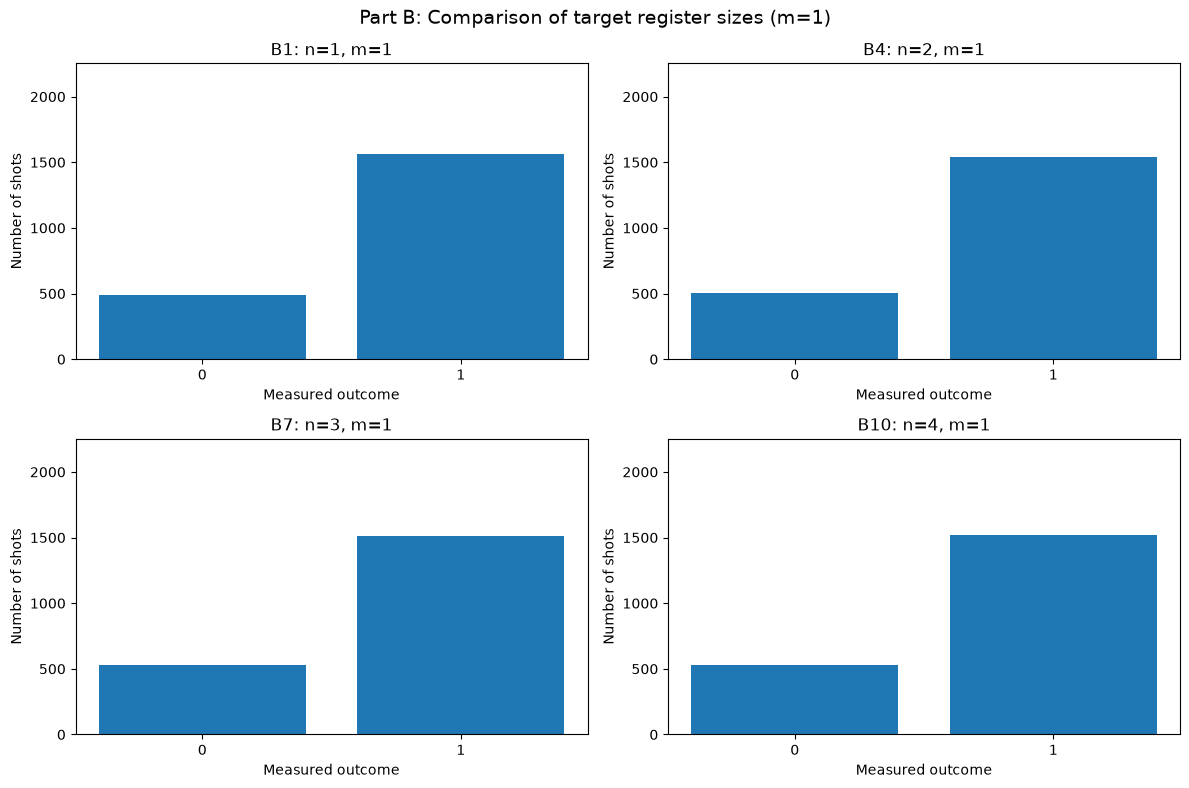

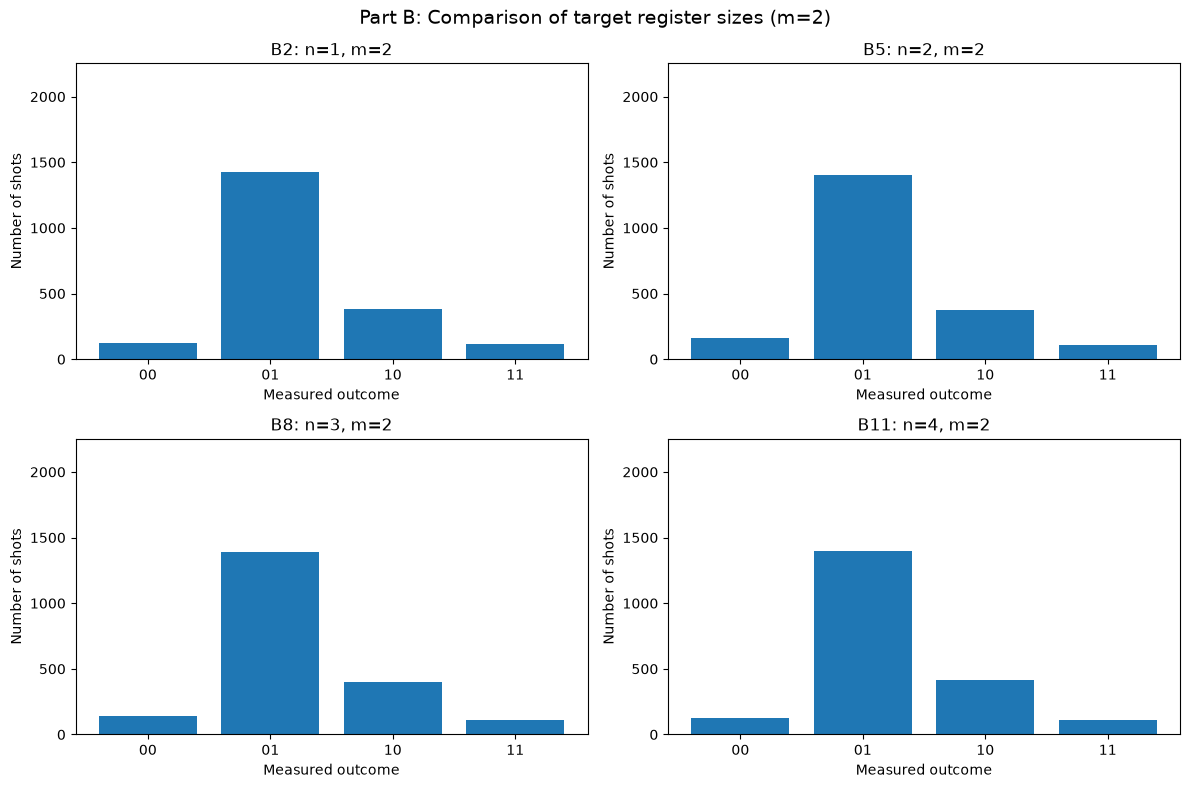

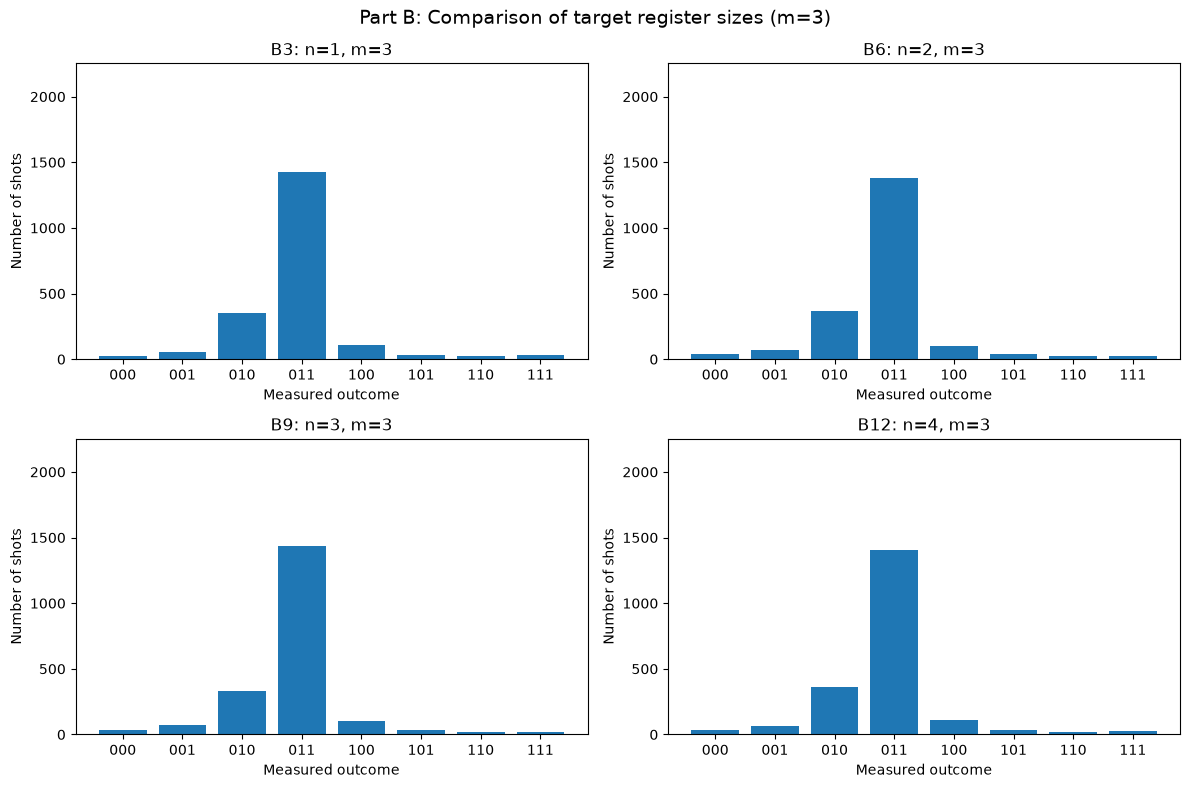

In [16]:

for m in range(1, 4):

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for n, ax in zip(range(1, 5), axes):

        run_id = f"B{(n-1)*3 + m}"
        counts = results_B[run_id]["counts"]

        outcomes = [
            format(y, f"0{m}b")
            for y in range(2**m)
        ]

        frequencies = [
            counts.get(outcome, 0)
            for outcome in outcomes
        ]

        ax.bar(outcomes, frequencies)
        ax.set_title(f"{run_id}: n={n}, m={m}")
        ax.set_xlabel("Measured outcome")
        ax.set_ylabel("Number of shots")
        ax.set_ylim(0, shots * 1.1)

    fig.suptitle(
        f"Part B: Comparison of target register sizes (m={m})",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


Additional experiment: n = 4, |v⟩ = |1110⟩, m = 3

In [17]:

# Additional Part B experiment
# n = 4, |v> = |1110>, m = 3

def qpe_circuit_B_extra(n, m, x):

    qc = QuantumCircuit(m+n, m)

    count = list(range(m))
    target = list(range(m, m+n))

    # Prepare |1110> (x = 14)
    prepare_basis_state(qc, target, x)

    # Hadamards on counting register
    for k in range(m):
        qc.h(count[k])

    theta = 2 * np.pi / 3

    # Controlled powers of MCP
    for k in range(m):

        angle = (2**k) * theta

        controls = [count[k]] + target[:-1]
        qc.mcp(angle, controls, target[-1])

    # Inverse QFT
    inverse_qft(qc, count)

    # Measurements
    for k in range(m):
        qc.measure(count[k], k)

    return qc


# Run the additional experiment
qc_B_extra = qpe_circuit_B_extra(4, 3, 14)

counts_B_extra = run(qc_B_extra, shots=shots)

print("Additional experiment: n=4, m=3, |v>=|1110>")
print("Measurement results:", counts_B_extra)


Additional experiment: n=4, m=3, |v>=|1110>
Measurement results: {'000': 2048}
